# NYC Motor Vehicle Crashes: Data Analysis
**Student:** Sudip  
**Course:** CIS 3400  
**Project:** Project 1, Deliverable 2  
**Term:** Fall 2026

This notebook analyzes 2026 year-to-date records from the NYC Open Data **Motor Vehicle Collisions – Crashes (NYPD)** dataset.

**Dataset source:** [NYC Open Data – Motor Vehicle Collisions – Crashes](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95)

The analysis answers the three questions from Deliverable 1:
1. When do crashes involving injuries or deaths happen?
2. Which contributing factors are reported in crashes involving injured or killed pedestrians, cyclists, and motorists?
3. Where do crashes involving injuries or deaths happen most often?

**Scope and limitations:** The supplied CSV covers January 2, 2023 through June 11, 2026. This notebook uses only 2026 records, so the year is incomplete. Reported contributing factors are not proof of legal fault or the only cause of a crash.

## Contents
1. Load and understand the data
2. Clean and prepare the data
3. Descriptive statistics and missingness
4. Explore the three proposal questions
5. Dashboard visualizations with filters
6. Select the three dashboard charts
7. Save and validate the dashboard dataset
8. Dashboard hand-off notes

## 1. Load and understand the data
Import the libraries and load the CSV. The code checks for an existing matching CSV first; in Google Colab, it asks you to upload the dataset if it cannot find one.

In [ ]:
from pathlib import Path
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_URL = "https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95"

candidates = [Path("Motor_Vehicle_Collisions.csv"), Path("Motor_Vehicle_Collisions(1).csv")]
candidates += sorted(Path(".").glob("Motor_Vehicle_Collisions*.csv"))
RAW_FILE = next((str(p) for p in candidates if p.exists()), None)

if RAW_FILE is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("No CSV file was uploaded.")
        RAW_FILE = next(iter(uploaded))
    except ImportError as exc:
        raise FileNotFoundError(
            "Place the Motor_Vehicle_Collisions CSV beside this notebook, "
            "or open it in Google Colab and upload the CSV."
        ) from exc

df_raw = pd.read_csv(RAW_FILE, low_memory=False)
print(f"File loaded: {RAW_FILE}")
print(f"Rows: {len(df_raw):,} | Columns: {len(df_raw.columns)}")
df_raw.head()

File loaded: Motor_Vehicle_Collisions.csv
Rows: 309,618 | Columns: 29


,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED,NUMBER OF PEDESTRIANS INJURED,NUMBER OF PEDESTRIANS KILLED,NUMBER OF CYCLIST INJURED,NUMBER OF CYCLIST KILLED,NUMBER OF MOTORIST INJURED,NUMBER OF MOTORIST KILLED,CONTRIBUTING FACTOR VEHICLE 1,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,01/02/2023,0:13,BRONX,10470.0,40.902397,-73.846680,"(40.902397, -73.84668)",NaN,NaN,4526 HOXIE STREET,0,0.0,0,0,0,0,0,0,Traffic Control Disregarded,Unspecified,Unspecified,NaN,NaN,4598277,Station Wagon/Sport Utility Vehicle,Taxi,Station Wagon/Sport Utility Vehicle,NaN,NaN
1,01/02/2023,10:00,QUEENS,11368.0,40.756060,-73.858590,"(40.75606, -73.85859)",NaN,NaN,34-36 110 STREET,0,0.0,0,0,0,0,0,0,Driver Inattention/Distraction,Unspecified,Unspecified,NaN,NaN,4598472,Station Wagon/Sport Utility Vehicle,Sedan,Pick-up Truck,NaN,NaN
2,01/02/2023,21:58,MANHATTAN,10030.0,40.819893,-73.946724,"(40.819893, -73.946724)",SAINT NICHOLAS AVENUE,WEST 139 STREET,NaN,1,0.0,0,0,1,0,0,0,Other Vehicular,Failure to Yield Right-of-Way,NaN,NaN,NaN,4598873,Sedan,Bike,NaN,NaN,NaN
3,01/02/2023,15:15,BRONX,10465.0,40.823658,-73.836426,"(40.823658, -73.836426)",NaN,NaN,815 HUTCHINSON RIVER PARKWAY,0,0.0,0,0,0,0,0,0,Unspecified,NaN,NaN,NaN,NaN,4598843,Sedan,NaN,NaN,NaN,NaN
4,01/02/2023,18:04,BRONX,10458.0,40.858807,-73.880150,"(40.858807, -73.88015)",NaN,NaN,2505 SOUTHERN BOULEVARD,1,0.0,0,0,0,0,1,0,Driver Inattention/Distraction,Unspecified,NaN,NaN,NaN,4598646,Taxi,Bus,NaN,NaN,NaN


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309618 entries, 0 to 309617
Data columns (total 29 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   CRASH DATE                     309618 non-null  object 
 1   CRASH TIME                     309618 non-null  object 
 2   BOROUGH                        227025 non-null  object 
 3   ZIP CODE                       226976 non-null  float64
 4   LATITUDE                       294001 non-null  float64
 5   LONGITUDE                      294001 non-null  float64
 6   LOCATION                       294001 non-null  object 
 7   ON STREET NAME                 218962 non-null  object 
 8   CROSS STREET NAME              164238 non-null  object 
 9   OFF STREET NAME                90654 non-null   object 
 10  NUMBER OF PERSONS INJURED      309618 non-null  int64  
 11  NUMBER OF PERSONS KILLED       300738 non-null  float64
 12  NUMBER OF PEDESTRIANS INJURED 

In [ ]:
raw_dates = pd.to_datetime(df_raw["CRASH DATE"], format="%m/%d/%Y", errors="coerce")
print("Exact duplicate rows:", f"{df_raw.duplicated().sum():,}")
print("Repeated collision IDs:", f"{df_raw['COLLISION_ID'].duplicated().sum():,}")
print("Missing or invalid crash dates:", f"{raw_dates.isna().sum():,}")
print("Date range:", raw_dates.min().date(), "to", raw_dates.max().date())
print("\nRows by year:")
print(raw_dates.dt.year.value_counts().sort_index().to_string())

Exact duplicate rows: 0
Repeated collision IDs: 0
Missing or invalid crash dates: 0
Date range: 2023-01-02 to 2026-06-11

Rows by year:
CRASH DATE
2023    96332
2024    91316
2025    85546
2026    36424


### Main columns used

| Column | Meaning |
|---|---|
| `CRASH DATE`, `CRASH TIME` | Date and time of the reported crash |
| `BOROUGH`, `ZIP CODE`, latitude and longitude | Reported location details |
| Street names | Nearby street/location descriptions |
| `NUMBER OF ... INJURED/KILLED` | Recorded counts for all people and for pedestrians, cyclists, and motorists |
| `CONTRIBUTING FACTOR VEHICLE 1` | Factor reported for Vehicle 1; this is not a finding of fault |
| `COLLISION_ID` | Identifier used to check duplicate crash records |

The source has other vehicle and factor columns. To keep this notebook focused, the analysis uses Vehicle 1's factor consistently.

## 2. Clean and prepare the data
Keep only the fields needed for these questions, convert dates and numeric fields, standardize text, remove rows that cannot be placed on a timeline, and filter to 2026. Rows are not removed just because a location or factor is missing.

In [ ]:
column_names = {
    "CRASH DATE": "crash_date",
    "CRASH TIME": "crash_time",
    "BOROUGH": "borough",
    "ZIP CODE": "zip_code",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude",
    "ON STREET NAME": "on_street",
    "CROSS STREET NAME": "cross_street",
    "NUMBER OF PERSONS INJURED": "persons_injured",
    "NUMBER OF PERSONS KILLED": "persons_killed",
    "NUMBER OF PEDESTRIANS INJURED": "pedestrians_injured",
    "NUMBER OF PEDESTRIANS KILLED": "pedestrians_killed",
    "NUMBER OF CYCLIST INJURED": "cyclists_injured",
    "NUMBER OF CYCLIST KILLED": "cyclists_killed",
    "NUMBER OF MOTORIST INJURED": "motorists_injured",
    "NUMBER OF MOTORIST KILLED": "motorists_killed",
    "CONTRIBUTING FACTOR VEHICLE 1": "factor_1",
    "VEHICLE TYPE CODE 1": "vehicle_type_1",
    "COLLISION_ID": "collision_id"
}

df = df_raw.rename(columns=column_names)[list(column_names.values())].copy()
df["crash_date"] = pd.to_datetime(df["crash_date"], format="%m/%d/%Y", errors="coerce")
invalid_dates_removed = int(df["crash_date"].isna().sum())
df = df.dropna(subset=["crash_date"])

duplicate_ids_removed = int(df["collision_id"].duplicated().sum())
df = df.drop_duplicates(subset="collision_id")

text_columns = ["borough", "on_street", "cross_street", "factor_1", "vehicle_type_1"]
for col in text_columns:
    df[col] = df[col].astype("string").str.strip().replace("", pd.NA)
df["borough"] = df["borough"].str.title()

for col in ["zip_code", "latitude", "longitude"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["zip_code"] = df["zip_code"].astype("Int64")

count_columns = [
    "persons_injured", "persons_killed",
    "pedestrians_injured", "pedestrians_killed",
    "cyclists_injured", "cyclists_killed",
    "motorists_injured", "motorists_killed"
]
for col in count_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["hour"] = pd.to_numeric(
    df["crash_time"].astype("string").str.extract(r"^(\d{1,2})")[0],
    errors="coerce"
)
df.loc[~df["hour"].between(0, 23), "hour"] = pd.NA
df["hour"] = df["hour"].astype("Int64")
df["day_of_week"] = df["crash_date"].dt.day_name()
df["month"] = df["crash_date"].dt.to_period("M").astype(str)

# The proposal focuses on 2026 only.
df = df[df["crash_date"].dt.year == 2026].copy()

# A crash counts as injury/death-related if at least one injury or a positive known death count is recorded.
# Missing death values remain missing in the source columns; they are not filled in the dataset itself.
road_user_death_columns = ["pedestrians_killed", "cyclists_killed", "motorists_killed"]
df["road_user_deaths"] = df[road_user_death_columns].fillna(0).sum(axis=1)
df["fatal_crash"] = df["persons_killed"].fillna(0).gt(0) | df["road_user_deaths"].gt(0)
df["injury_death_crash"] = df["persons_injured"].fillna(0).gt(0) | df["fatal_crash"]

injury_crashes = df[df["injury_death_crash"]].copy()

print(f"Invalid dates removed: {invalid_dates_removed:,}")
print(f"Duplicate collision IDs removed: {duplicate_ids_removed:,}")
print(f"2026 records retained: {len(df):,}")
print(f"Date range: {df['crash_date'].min().date()} to {df['crash_date'].max().date()}")
print(f"Crashes involving injuries or a known positive death count: {len(injury_crashes):,}")

Invalid dates removed: 0
Duplicate collision IDs removed: 0
2026 records retained: 36,424
Date range: 2026-01-01 to 2026-06-11
Crashes involving injuries or a known positive death count: 15,304


## 3. Descriptive statistics and missingness
Missing values need to be understood before making charts. We check how much data is missing, then make decisions based on what each field is used for.

### 3.1 A quick summary

In [ ]:
print(f"All 2026 crash records: {len(df):,}")
print(f"Injury/death crash records: {len(injury_crashes):,}")
print(f"Crash records with a known positive death count: {int(df['fatal_crash'].sum()):,}")
print("\nRecorded injury counts:")
display(df[["persons_injured", "pedestrians_injured", "cyclists_injured", "motorists_injured"]].describe().T.round(2))

All 2026 crash records: 36,424
Injury/death crash records: 15,304
Crash records with a known positive death count: 86

Recorded injury counts:


,count,mean,std,min,25%,50%,75%,max
persons_injured,36424.0,0.57,0.86,0.0,0.0,0.0,1.0,21.0
pedestrians_injured,36424.0,0.11,0.32,0.0,0.0,0.0,0.0,4.0
cyclists_injured,36424.0,0.05,0.23,0.0,0.0,0.0,0.0,3.0
motorists_injured,36424.0,0.39,0.84,0.0,0.0,0.0,1.0,21.0


### 3.2 Missingness: how much is missing?
The table shows missing counts and percentages for the cleaned 2026 data. The chart is a data-quality check, not one of the three dashboard charts.

,missing_count,missing_percent
cross_street,16843,46.24
on_street,11748,32.25
persons_killed,8877,24.37
zip_code,8700,23.89
borough,8693,23.87
vehicle_type_1,683,1.88
latitude,328,0.90
longitude,328,0.90
factor_1,236,0.65


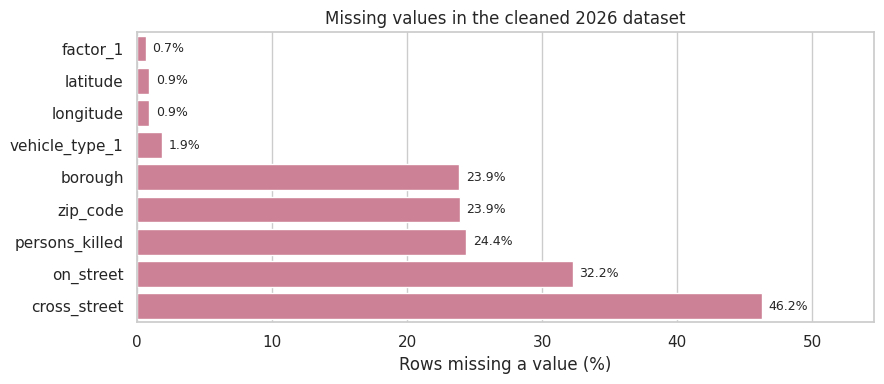

In [ ]:
missingness = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
})
missingness = missingness[missingness["missing_count"] > 0].sort_values(
    "missing_percent", ascending=False
)
display(missingness)

if not missingness.empty:
    plot_missing = missingness["missing_percent"].sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(9, max(4, 0.38 * len(plot_missing))))
    sns.barplot(x=plot_missing.values, y=plot_missing.index, color="#D87591", ax=ax)
    for i, value in enumerate(plot_missing.values):
        ax.text(value + 0.5, i, f"{value:.1f}%", va="center", fontsize=9)
    ax.set_title("Missing values in the cleaned 2026 dataset")
    ax.set_xlabel("Rows missing a value (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, max(plot_missing.values) * 1.18)
    plt.tight_layout()
    plt.show()

### 3.3 What we do with missing values

| Field or issue | Decision | Why |
|---|---|---|
| Crash date | Convert to a date; remove rows only if the date is invalid | A record without a usable date cannot be placed in the time analysis. |
| Duplicate collision ID | Remove repeated IDs if any are found | Avoid counting the same crash more than once. |
| Borough and street names | Keep missing values; do not guess or fill them | The crash can still be used for time/factor analysis, but location summaries use records with known location values. |
| Latitude and longitude | Keep missing coordinates; do not invent locations | They are not needed for the three charts in this notebook. A future map should use only records with valid coordinates. |
| Hour | Keep invalid or missing hours as missing | The record can still be counted elsewhere, but it cannot be assigned to an hour in the heatmap. |
| Vehicle 1 factor | Keep blanks missing. Keep `Unspecified` as its own recorded category, but exclude blanks and `Unspecified` from the ranked factor chart | A blank and a recorded “Unspecified” value are not the same thing. Neither should be replaced with a guessed factor. |
| Death counts | Leave blanks missing in the source columns | A blank is not evidence that a death occurred. For the injury/death flag, a death counts only when a positive death count is recorded; positive injury counts also qualify. |
| Other numeric fields | Coerce invalid text to missing; do not fill with the mean or zero | Filling values could invent crash details or distort summaries. |

**Overall decision:** do not drop every row containing a missing value and do not fill missing values with guesses. Keep records for analyses where the required fields are present, and exclude a row only from a calculation or chart that needs a missing field.

In [ ]:
# Compare missingness in key fields for all 2026 crashes and injury/death crashes.
key_fields = ["borough", "latitude", "longitude", "on_street", "cross_street", "persons_killed", "factor_1"]
missingness_comparison = pd.DataFrame({
    "all_2026_missing_percent": (df[key_fields].isna().mean() * 100).round(2),
    "injury_death_missing_percent": (injury_crashes[key_fields].isna().mean() * 100).round(2)
})
display(missingness_comparison)

unspecified_count = int(df["factor_1"].eq("Unspecified").sum())
blank_factor_count = int(df["factor_1"].isna().sum())
print(f"Vehicle 1 factor recorded as 'Unspecified': {unspecified_count:,} rows")
print(f"Vehicle 1 factor blank: {blank_factor_count:,} rows")
print(f"Injury/death crashes with missing borough: {injury_crashes['borough'].isna().sum():,}")
print(f"Injury/death crashes with missing hour: {injury_crashes['hour'].isna().sum():,}")

,all_2026_missing_percent,injury_death_missing_percent
borough,23.87,26.68
latitude,0.90,1.10
longitude,0.90,1.10
on_street,32.25,21.01
cross_street,46.24,36.98
persons_killed,24.37,27.01
factor_1,0.65,1.35


Vehicle 1 factor recorded as 'Unspecified': 9,999 rows
Vehicle 1 factor blank: 236 rows
Injury/death crashes with missing borough: 4,083
Injury/death crashes with missing hour: 0


## 4. Explore the three proposal questions
This section uses small summary tables to support the charts in Section 5. The graphs are only created once, so the notebook avoids repeating the same visualizations.

### Q1 — When do injury/death crashes happen?
The dashboard heatmap compares crashes by weekday and hour. These tables identify the most frequent recorded day and hour; they are counts, not rates of risk.

In [ ]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
q1_day_counts = injury_crashes["day_of_week"].value_counts().reindex(day_order, fill_value=0).rename("crashes")
q1_hour_counts = injury_crashes["hour"].value_counts().sort_values(ascending=False).head(5).rename_axis("hour").reset_index(name="crashes")
print("Crashes by weekday:")
display(q1_day_counts.to_frame())
print("Top five hours:")
display(q1_hour_counts)

Crashes by weekday:


,crashes
day_of_week,
Monday,2099
Tuesday,2293
Wednesday,2193
Thursday,2298
Friday,2525
Saturday,2074
Sunday,1822


Top five hours:


,hour,crashes
0,17,1017
1,15,1013
2,18,974
3,16,953
4,14,941


### Q2 — Which factors are reported for crashes involving injured or killed road users?
A crash may appear in more than one road-user group if, for example, both a pedestrian and a motorist were injured. Factor counts use Vehicle 1's reported factor and omit blank or `Unspecified` values from the ranked comparison.

In [ ]:
user_groups = {
    "Pedestrians": ("pedestrians_injured", "pedestrians_killed"),
    "Cyclists": ("cyclists_injured", "cyclists_killed"),
    "Motorists": ("motorists_injured", "motorists_killed")
}

factor_parts = []
for road_user, (injured_col, killed_col) in user_groups.items():
    mask = df[injured_col].fillna(0).gt(0) | df[killed_col].fillna(0).gt(0)
    part = df.loc[mask, ["collision_id", "borough", "factor_1"]].copy()
    part["road_user"] = road_user
    factor_parts.append(part)

factor_long = pd.concat(factor_parts, ignore_index=True)
factor_long = factor_long.dropna(subset=["factor_1"])
factor_long = factor_long[factor_long["factor_1"].str.casefold() != "unspecified"]

print("Most frequent reported Vehicle 1 factors by road-user group:")
display(
    factor_long.groupby(["road_user", "factor_1"]).size()
    .rename("crashes").reset_index()
    .sort_values(["road_user", "crashes"], ascending=[True, False])
    .groupby("road_user", group_keys=False).head(5)
)

Most frequent reported Vehicle 1 factors by road-user group:


,road_user,factor_1,crashes
10,Cyclists,Driver Inattention/Distraction,515
14,Cyclists,Failure to Yield Right-of-Way,225
30,Cyclists,Pedestrian/Bicyclist/Other Pedestrian Error/Co...,164
27,Cyclists,Passing or Lane Usage Improper,89
35,Cyclists,Traffic Control Disregarded,81
53,Motorists,Driver Inattention/Distraction,2229
62,Motorists,Following Too Closely,737
59,Motorists,Failure to Yield Right-of-Way,481
71,Motorists,Other Vehicular,479
92,Motorists,Unsafe Speed,361


### Q3 — Where do injury/death crashes happen most often?
The borough chart compares crashes with a known borough. The street table adds detail about reported locations. Records with missing borough or street names remain in the data but cannot be ranked in those summaries.

In [ ]:
q3_borough_counts = injury_crashes["borough"].dropna().value_counts().rename_axis("borough").reset_index(name="crashes")
q3_street_counts = injury_crashes["on_street"].dropna().value_counts().head(10).rename_axis("reported_street").reset_index(name="crashes")
print("Injury/death crashes by reported borough:")
display(q3_borough_counts)
print("Top 10 reported on-street names:")
display(q3_street_counts)

Injury/death crashes by reported borough:


,borough,crashes
0,Brooklyn,4030
1,Queens,2775
2,Manhattan,2126
3,Bronx,1901
4,Staten Island,389


Top 10 reported on-street names:


,reported_street,crashes
0,BELT PARKWAY,198
1,LONG ISLAND EXPRESSWAY,180
2,BROOKLYN QUEENS EXPRESSWAY,145
3,BROADWAY,141
4,GRAND CENTRAL PKWY,127
5,CROSS BRONX EXPY,114
6,MAJOR DEEGAN EXPRESSWAY,107
7,ATLANTIC AVE,97
8,FDR DRIVE,89
9,FLATBUSH AVE,87


## 5. Visualizations with filters (the dashboard charts)
Each dashboard chart is built as **filter → aggregate → plot**. The `apply_filters()` function supports borough and road-user filters. Set a filter to `None` to include all values. The examples below show the citywide view; the same functions can be connected to Streamlit sidebar controls later.

In [ ]:
def apply_filters(data, boroughs=None, road_users=None):
    """Filter data by borough and/or road-user group. None means no restriction."""
    out = data
    if boroughs is not None and "borough" in out.columns:
        out = out[out["borough"].isin(boroughs)]
    if road_users is not None:
        if "road_user" in out.columns:
            out = out[out["road_user"].isin(road_users)]
        else:
            masks = []
            for road_user in road_users:
                if road_user in user_groups:
                    injured_col, killed_col = user_groups[road_user]
                    masks.append(out[injured_col].fillna(0).gt(0) | out[killed_col].fillna(0).gt(0))
            if masks:
                combined = masks[0]
                for mask in masks[1:]:
                    combined = combined | mask
                out = out[combined]
    return out

all_boroughs = sorted(injury_crashes["borough"].dropna().unique().tolist())
all_road_users = ["Pedestrians", "Cyclists", "Motorists"]

### Chart 1 — Injury/death crashes by weekday and hour (Q1)
**What it shows:** Each cell counts injury/death crashes reported on that weekday and hour.  
**Why it matters:** It helps transportation planners see when crash records are most concentrated. A high count does not by itself show a higher risk because traffic volume is not included.

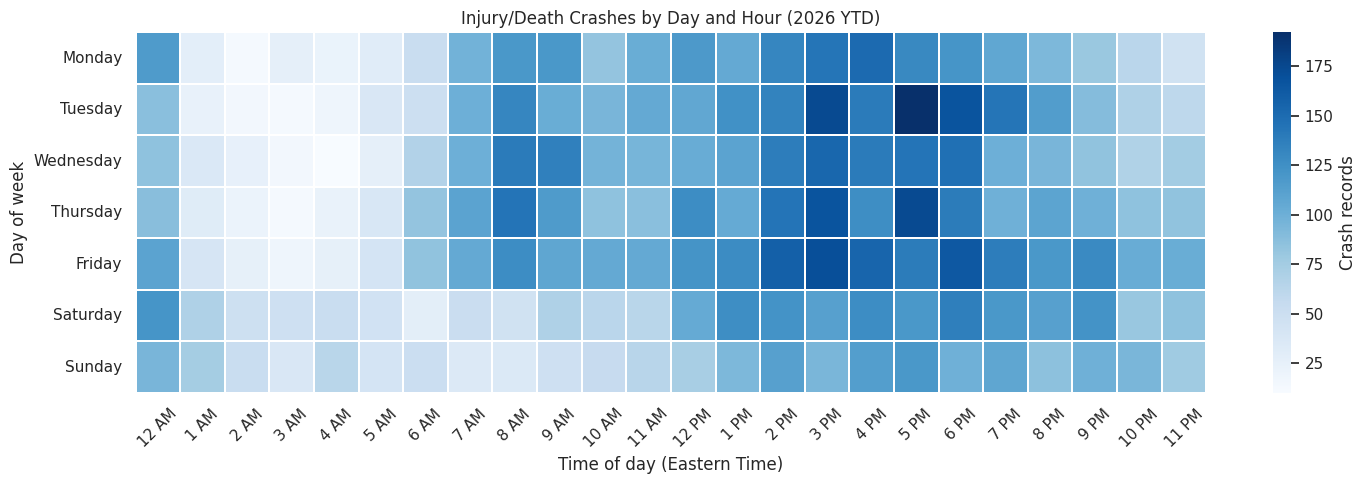

Crashes included: 15,304 | Excluded from heatmap due to missing hour: 0


In [ ]:
def plot_time_heatmap(boroughs=None, road_users=None):
    data = apply_filters(injury_crashes, boroughs=boroughs, road_users=road_users)

    counts = pd.crosstab(data["day_of_week"], data["hour"])
    counts = counts.reindex(index=day_order, columns=range(24), fill_value=0)

    # Convert 24-hour format into 12-hour AM/PM labels.
    hour_labels = [
        f"{(h % 12) or 12} {'AM' if h < 12 else 'PM'}"
        for h in range(24)
    ]

    # Create heatmap.
    fig, ax = plt.subplots(figsize=(15, 5))

    sns.heatmap(
        counts,
        cmap="Blues",
        linewidths=0.2,
        xticklabels=hour_labels,
        cbar_kws={"label": "Crash records"},
        ax=ax
    )

    ax.set_title("Injury/Death Crashes by Day and Hour (2026 YTD)")
    ax.set_xlabel("Time of day (Eastern Time)")
    ax.set_ylabel("Day of week")

    # Improve readability of time labels.
    ax.tick_params(axis="x", labelrotation=45)

    plt.tight_layout()
    plt.show()

    print(
        f"Crashes included: {len(data):,} | "
        f"Excluded from heatmap due to missing hour: "
        f"{data['hour'].isna().sum():,}"
    )

    return counts


q1_heatmap = plot_time_heatmap()

### Chart 2 — Reported contributing factors by road-user group (Q2)
**What it shows:** The most frequent Vehicle 1 reported factors are compared for crashes involving injured or killed pedestrians, cyclists, and motorists.  
**Why it matters:** It can guide further investigation of reported patterns. The data does not prove legal fault or establish that the listed factor caused the crash.

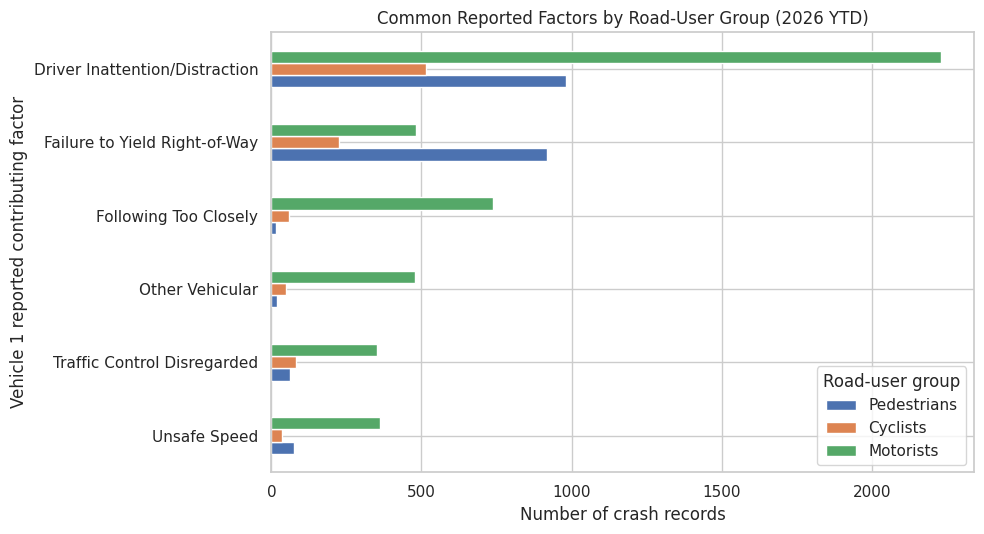

In [ ]:
def plot_factor_chart(boroughs=None, road_users=None, top_n=6):
    data = apply_filters(factor_long, boroughs=boroughs, road_users=road_users)
    if data.empty:
        print("No rows match these filters.")
        return pd.DataFrame()

    top_factors = data["factor_1"].value_counts().head(top_n).index.tolist()
    counts = (
        data[data["factor_1"].isin(top_factors)]
        .groupby(["factor_1", "road_user"]).size()
        .unstack(fill_value=0)
    )
    counts = counts.reindex(counts.sum(axis=1).sort_values().index)
    counts = counts.reindex(columns=all_road_users, fill_value=0)

    ax = counts.plot(kind="barh", figsize=(10, 5.5))
    ax.set_title("Common Reported Factors by Road-User Group (2026 YTD)")
    ax.set_xlabel("Number of crash records")
    ax.set_ylabel("Vehicle 1 reported contributing factor")
    ax.legend(title="Road-user group")
    plt.tight_layout()
    plt.show()
    return counts

factor_chart_table = plot_factor_chart(road_users=all_road_users)

### Chart 3 — Injury/death crashes by borough (Q3)
**What it shows:** Counts injury/death crashes with a known borough.  
**Why it matters:** It gives a clear borough-level comparison for residents and transportation planners. Borough counts do not account for differences in population, road length, or traffic volume.

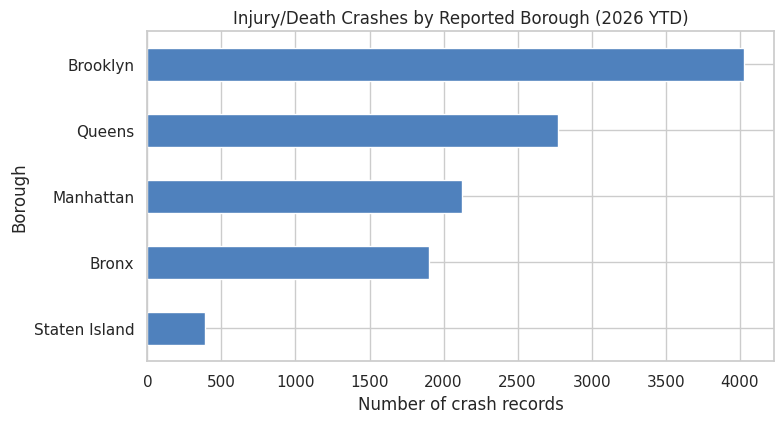

Injury/death crashes with missing borough: 4,083


In [ ]:
def plot_borough_chart(road_users=None):
    data = apply_filters(injury_crashes, road_users=road_users)
    counts = data["borough"].dropna().value_counts().sort_values()

    fig, ax = plt.subplots(figsize=(8, 4.4))
    counts.plot(kind="barh", ax=ax, color="#4F81BD")
    ax.set_title("Injury/Death Crashes by Reported Borough (2026 YTD)")
    ax.set_xlabel("Number of crash records")
    ax.set_ylabel("Borough")
    plt.tight_layout()
    plt.show()
    print(f"Injury/death crashes with missing borough: {data['borough'].isna().sum():,}")
    return counts.rename("crashes").to_frame()

borough_chart_table = plot_borough_chart()

### Additional Visual 1 — Monthly trend of injury/death crashes

**What it shows:** The number of crashes involving injuries or deaths recorded each month in 2026.

**Why it matters:** This visualization helps identify whether recorded injury/death crashes increase or decrease over the year. It provides a monthly perspective that complements the weekday-and-hour heatmap.

**Limitation:** The dataset only covers January 2 through June 11, 2026. June is incomplete, so its count should not be directly compared with full months.

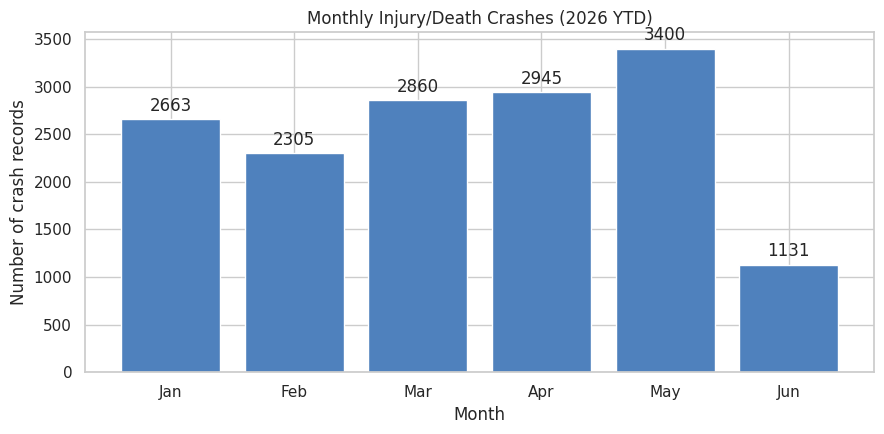

Data ends: June 11, 2026
Note: June represents only a partial month.


In [ ]:
# Count injury/death crashes by month.
monthly_crashes = (
    injury_crashes.groupby(
        injury_crashes["crash_date"].dt.to_period("M")
    ).size()
)

# Include months with zero records, if any.
all_months = pd.period_range(
    start=monthly_crashes.index.min(),
    end=monthly_crashes.index.max(),
    freq="M"
)

monthly_crashes = monthly_crashes.reindex(all_months, fill_value=0)
monthly_labels = monthly_crashes.index.to_timestamp().strftime("%b")

# Create the visualization.
fig, ax = plt.subplots(figsize=(9, 4.5))

bars = ax.bar(monthly_labels, monthly_crashes.values, color="#4F81BD")

ax.bar_label(bars, padding=3, fmt="%.0f")
ax.set_title("Monthly Injury/Death Crashes (2026 YTD)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of crash records")

plt.tight_layout()
plt.show()

print("Data ends:", df["crash_date"].max().strftime("%B %d, %Y"))
print("Note: June represents only a partial month.")

### Additional Visual 2 — Top 10 reported street names

**What it shows:** The ten most frequently reported street names associated with injury/death crashes in 2026.

**Why it matters:** This visualization provides more specific location information than the borough chart. It can help identify street names that appear frequently in crash records.

**Limitation:** These are reported street-name counts, not crash-risk rates. Traffic volume, road length, and the number of vehicles using each street are not included.

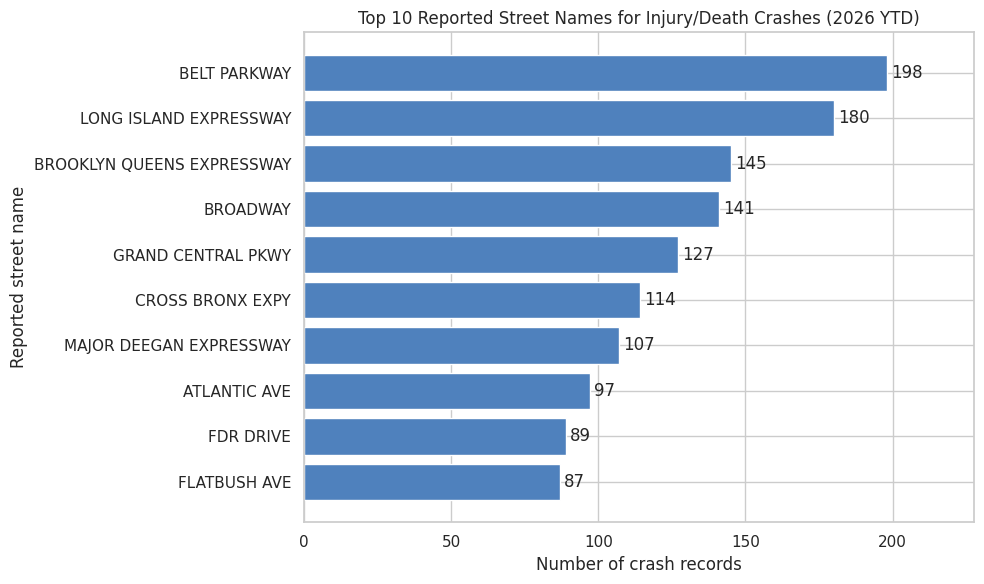

In [ ]:
# Get the top 10 reported street names.
top_streets = (
    injury_crashes["on_street"]
    .dropna()
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Create a horizontal bar chart.
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_streets.index,
    top_streets.values,
    color="#4F81BD"
)

ax.bar_label(bars, padding=3, fmt="%.0f")

ax.set_title("Top 10 Reported Street Names for Injury/Death Crashes (2026 YTD)")
ax.set_xlabel("Number of crash records")
ax.set_ylabel("Reported street name")
ax.set_xlim(0, top_streets.max() * 1.15)

plt.tight_layout()
plt.show()

## 6. Which charts go in the dashboard?

| Rank | Dashboard chart | Proposal question | Suggested filter |
|---|---|---|---|
| 1 | Weekday-by-hour heatmap | Q1: When do injury/death crashes happen? | Borough; road-user group |
| 2 | Reported factors by road-user group | Q2: Which factors are reported? | Borough; road-user group |
| 3 | Injury/death crashes by borough | Q3: Where do these crashes happen? | Road-user group |

These charts answer the three proposal questions without adding multiple graphs for the same question. The top-street table can be shown as supporting information. Suggested KPI cards: total 2026 crash records, injury/death crash records, and known-positive fatal crash records.

## 7. Save and validate the dashboard dataset
Keep all 2026 crash records so the dashboard can compare all crashes with injury/death crashes. The export includes only the fields required for time, location, road-user, and factor filters.

In [ ]:
DASHBOARD_FILE = "dashboard_crashes_2026.csv"
dashboard_columns = [
    "collision_id", "crash_date", "crash_time", "hour", "day_of_week", "month",
    "borough", "zip_code", "latitude", "longitude", "on_street", "cross_street",
    "persons_injured", "persons_killed",
    "pedestrians_injured", "pedestrians_killed",
    "cyclists_injured", "cyclists_killed",
    "motorists_injured", "motorists_killed",
    "factor_1", "vehicle_type_1", "fatal_crash", "injury_death_crash"
]

dash = df[dashboard_columns].copy()
dash["crash_date"] = dash["crash_date"].dt.strftime("%Y-%m-%d")
dash["latitude"] = dash["latitude"].round(6)
dash["longitude"] = dash["longitude"].round(6)
dash.to_csv(DASHBOARD_FILE, index=False)

file_size_mb = os.path.getsize(DASHBOARD_FILE) / (1024 * 1024)
print("Saved:", DASHBOARD_FILE)
print(f"Rows: {len(dash):,} | Columns: {len(dash.columns)} | File size: {file_size_mb:.2f} MB")
print("Under 25 MB target:", file_size_mb < 25)

Saved: dashboard_crashes_2026.csv
Rows: 36,424 | Columns: 24 | File size: 5.42 MB
Under 25 MB target: True


In [ ]:
dashboard_check = pd.read_csv(DASHBOARD_FILE, parse_dates=["crash_date"])
print("Reloaded shape:", dashboard_check.shape)
print("Date range:", dashboard_check["crash_date"].min().date(), "to", dashboard_check["crash_date"].max().date())
print("Injury/death crash records:", f"{int(dashboard_check['injury_death_crash'].sum()):,}")
print("Rows with missing borough:", f"{dashboard_check['borough'].isna().sum():,}")
print("Rows with missing coordinates:", f"{dashboard_check[['latitude', 'longitude']].isna().any(axis=1).sum():,}")
print("\nMissing dashboard values are retained where appropriate:")
display(dashboard_check.isna().sum()[dashboard_check.isna().sum() > 0].rename("missing_count").to_frame())

Reloaded shape: (36424, 24)
Date range: 2026-01-01 to 2026-06-11
Injury/death crash records: 15,304
Rows with missing borough: 8,693
Rows with missing coordinates: 328

Missing dashboard values are retained where appropriate:


,missing_count
borough,8693
zip_code,8700
latitude,328
longitude,328
on_street,11748
cross_street,16843
persons_killed,8877
factor_1,236
vehicle_type_1,683


## 8. Dashboard hand-off notes

- **Data file:** `dashboard_crashes_2026.csv` (same folder as `app.py`).
- **Source:** [NYC Open Data – Motor Vehicle Collisions – Crashes](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95).
- **Time fields:** `crash_date`, `crash_time`, `hour`, `day_of_week`, `month`.
- **Location fields:** `borough`, `zip_code`, `latitude`, `longitude`, `on_street`, `cross_street`.
- **Injury/death flag:** `injury_death_crash` is true when a positive injury count or a positive known death count is recorded.
- **Reported factor:** `factor_1` is the factor entered for Vehicle 1; blank and `Unspecified` are not ranked in the factor chart.
- **Missingness:** do not globally fill missing values. Keep a crash for charts where the required fields are present; omit it only from a chart that needs a missing field.
- **Limitations:** the source currently ends on June 11, 2026, many borough/street details are missing, and traffic exposure is not included. Reported counts are not risk rates and reported factors do not establish fault.

In [ ]:
import pandas as pd

# Load both datasets
df = pd.read_csv("dashboard_crashes_2026.csv")
weather = pd.read_csv("noaa_nyc_hourly_weather_2026.csv")

# Make sure date and hour columns have matching formats
df["crash_date"] = pd.to_datetime(
    df["crash_date"], errors="coerce"
).dt.strftime("%Y-%m-%d")

weather["crash_date"] = pd.to_datetime(
    weather["crash_date"], errors="coerce"
).dt.strftime("%Y-%m-%d")

df["hour"] = pd.to_numeric(df["hour"], errors="coerce").astype("Int64")
weather["hour"] = pd.to_numeric(weather["hour"], errors="coerce").astype("Int64")

# Check that each weather date/hour combination is unique
assert not weather.duplicated(["crash_date", "hour"]).any()

# Merge weather information into crash data
df = df.merge(
    weather,
    on=["crash_date", "hour"],
    how="left",
    validate="many_to_one"
)

# Check results
print("Total crash records:", len(df))
print("Weather columns added:", len(weather.columns) - 2)

weather_columns = [
    col for col in weather.columns
    if col not in ["crash_date", "hour"]
]

matched = df[weather_columns].notna().any(axis=1).sum()

print("Crashes with weather information:", matched)
print("Crashes without weather information:", len(df) - matched)

display(df.head())

Total crash records: 36424
Weather columns added: 34
Crashes with weather information: 36424
Crashes without weather information: 0


,collision_id,crash_date,crash_time,hour,day_of_week,month,borough,zip_code,latitude,longitude,on_street,cross_street,persons_injured,persons_killed,pedestrians_injured,pedestrians_killed,cyclists_injured,cyclists_killed,motorists_injured,motorists_killed,factor_1,vehicle_type_1,fatal_crash,injury_death_crash,local_observation_time,weather_observation_count,station_id,station_name,station_latitude,station_longitude,temperature_c,dew_point_c,relative_humidity_pct,precipitation_mm,wind_speed_m_s,wind_direction_deg,wind_gust_m_s,visibility_km,sea_level_pressure_hpa,station_pressure_hpa,altimeter_hpa,ceiling_height_m,snow_depth_mm,sky_condition_code,automated_weather_code_1,automated_weather_code_2,automated_weather_code_3,manual_weather_code_1,manual_weather_code_2,manual_weather_code_3,precipitation_measurement_code,temperature_qc,dew_point_qc,relative_humidity_qc,precipitation_qc,wind_speed_qc,visibility_qc,precipitation_trace
0,4870479,2026-01-01,20:46,20,Thursday,2026-01,Brooklyn,11234.0,40.630867,-73.92233,AVENUE I,E 56 ST,0,0.0,0,0,0,0,0,0,Turning Improperly,Station Wagon/Sport Utility Vehicle,False,False,1/1/2026 20:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,-5.6,-16.7,42.0,NaN,2.6,270.0,NaN,16.093,1011.6,NaN,1012.5,22000.0,NaN,00;;,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
1,4869168,2026-01-01,17:31,17,Thursday,2026-01,NaN,NaN,NaN,NaN,Broadway & Grand St,NaN,1,0.0,0,0,0,0,1,0,Unspecified,Sedan,False,True,1/1/2026 17:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,-4.4,-17.8,35.0,NaN,3.6,290.0,8.8,16.093,1011.0,NaN,1011.8,22000.0,NaN,00;;,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
2,4868793,2026-01-01,0:15,0,Thursday,2026-01,Staten Island,10306.0,40.565370,-74.11490,HYLAN BLVD,CANNON BLVD,0,0.0,0,0,0,0,0,0,Reaction to Uninvolved Vehicle,Station Wagon/Sport Utility Vehicle,False,False,1/1/2026 0:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,0.6,-7.8,54.0,NaN,1.5,999.0,NaN,16.093,1002.4,NaN,1003.0,1524.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
3,4868850,2026-01-01,8:54,8,Thursday,2026-01,Brooklyn,11207.0,40.651688,-73.88876,FLATLANDS AVE,ALABAMA AVE,1,0.0,0,0,0,0,1,0,Failure to Yield Right-of-Way,Station Wagon/Sport Utility Vehicle,False,True,1/1/2026 8:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,-4.4,-13.9,48.0,NaN,6.2,310.0,12.9,16.093,1006.0,NaN,1006.8,22000.0,NaN,00;;,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
4,4869094,2026-01-01,2:05,2,Thursday,2026-01,Brooklyn,11204.0,40.610844,-73.99177,20 AVE,BAY RIDGE PKWY,1,0.0,0,0,0,0,0,0,Traffic Control Disregarded,Standing S,False,True,1/1/2026 2:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,1.1,-6.7,56.0,NaN,2.1,999.0,NaN,16.093,1001.3,NaN,1002.0,3353.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN


In [ ]:
# Check the weather dataset
print("Weather dataset columns:")
print(weather.columns.tolist())

# Check the merged crash dataset
print("\nMerged dataset columns:")
print(df.columns.tolist())

# Show the weather columns that were added
weather_columns = [
    col for col in weather.columns
    if col not in ["crash_date", "hour"]
]

print("\nWeather columns in crash dataset:")
print([col for col in weather_columns if col in df.columns])

# Display a few crash records with their weather
display(
    df[["crash_date", "hour"] + [
        col for col in weather_columns if col in df.columns
    ]].head()
)

Weather dataset columns:
['crash_date', 'hour', 'local_observation_time', 'weather_observation_count', 'station_id', 'station_name', 'station_latitude', 'station_longitude', 'temperature_c', 'dew_point_c', 'relative_humidity_pct', 'precipitation_mm', 'wind_speed_m_s', 'wind_direction_deg', 'wind_gust_m_s', 'visibility_km', 'sea_level_pressure_hpa', 'station_pressure_hpa', 'altimeter_hpa', 'ceiling_height_m', 'snow_depth_mm', 'sky_condition_code', 'automated_weather_code_1', 'automated_weather_code_2', 'automated_weather_code_3', 'manual_weather_code_1', 'manual_weather_code_2', 'manual_weather_code_3', 'precipitation_measurement_code', 'temperature_qc', 'dew_point_qc', 'relative_humidity_qc', 'precipitation_qc', 'wind_speed_qc', 'visibility_qc', 'precipitation_trace']

Merged dataset columns:
['collision_id', 'crash_date', 'crash_time', 'hour', 'day_of_week', 'month', 'borough', 'zip_code', 'latitude', 'longitude', 'on_street', 'cross_street', 'persons_injured', 'persons_killed', 'pede

,crash_date,hour,local_observation_time,weather_observation_count,station_id,station_name,station_latitude,station_longitude,temperature_c,dew_point_c,relative_humidity_pct,precipitation_mm,wind_speed_m_s,wind_direction_deg,wind_gust_m_s,visibility_km,sea_level_pressure_hpa,station_pressure_hpa,altimeter_hpa,ceiling_height_m,snow_depth_mm,sky_condition_code,automated_weather_code_1,automated_weather_code_2,automated_weather_code_3,manual_weather_code_1,manual_weather_code_2,manual_weather_code_3,precipitation_measurement_code,temperature_qc,dew_point_qc,relative_humidity_qc,precipitation_qc,wind_speed_qc,visibility_qc,precipitation_trace
0,2026-01-01,20,1/1/2026 20:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,-5.6,-16.7,42.0,NaN,2.6,270.0,NaN,16.093,1011.6,NaN,1012.5,22000.0,NaN,00;;,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
1,2026-01-01,17,1/1/2026 17:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,-4.4,-17.8,35.0,NaN,3.6,290.0,8.8,16.093,1011.0,NaN,1011.8,22000.0,NaN,00;;,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
2,2026-01-01,0,1/1/2026 0:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,0.6,-7.8,54.0,NaN,1.5,999.0,NaN,16.093,1002.4,NaN,1003.0,1524.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
3,2026-01-01,8,1/1/2026 8:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,-4.4,-13.9,48.0,NaN,6.2,310.0,12.9,16.093,1006.0,NaN,1006.8,22000.0,NaN,00;;,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN
4,2026-01-01,2,1/1/2026 2:55,13,USW00094728,"NY CITY CENTRAL PARK, NY US",40.77898,-73.96925,1.1,-6.7,56.0,NaN,2.1,999.0,NaN,16.093,1001.3,NaN,1002.0,3353.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,NaN,NaN,1.0,1.0,NaN


In [ ]:
# Save merged crash and weather data
df.to_csv("nyc_crashes_with_weather_2026.csv", index=False)

print("Merged dataset saved successfully!")

Merged dataset saved successfully!
